In [9]:
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import torch
from IPython.display import display, HTML

warnings.filterwarnings('ignore')

In [10]:
# ===== PATH CONFIGURATION =====
BASE_DIR = Path('/mnt/lustre/work/hein/hof217/stable_diffusion')
NEW_QWEN_BASE = BASE_DIR / 'x7-z1-qwen_small/new_qwen_outputs'
MANUAL_DIR = BASE_DIR / 'z5-manual_annotations'

MANUAL_FILES = {
    'standard': 'standard.csv',
    'cogvlm': 'cogvlm_clic.csv',
    'redcaps': 'redcaps_clic.csv',
}

TENSOR_ROOTS = {
    'standard': BASE_DIR / 'x5.5-prompts_sd35_output/standard_sd35_output',
    'cogvlm': BASE_DIR / 'z4-cogvlm_custom_sd35/cogvlm_sd35_output',
    'redcaps': BASE_DIR / 'z0-custom_sd35_clic/custom_sd35_output',
}

TENSOR_INDEX_CACHE = {}

# ===== DATA LOADING HELPERS =====

def parse_manual_indices(s):
    if pd.isna(s) or str(s).strip() == '':
        return set()
    return set(int(x.strip()) for x in str(s).replace(';', ',').split(',') if x.strip().isdigit())

def load_manual_for_phrase(model, phrase):
    manual_path = MANUAL_DIR / MANUAL_FILES[model]
    if not manual_path.exists():
        return None
    df = pd.read_csv(manual_path)
    row = df[df['phrase'] == phrase]
    if row.empty or pd.isna(row.iloc[0].get('checked', np.nan)):
        return None
    row = row.iloc[0]
    return {
        'tensor_file': row['tensor_file'],
        'checked': int(row['checked']),
        'ambiguous': parse_manual_indices(row['[tensor_index-es for ambigious images]']),
        'incorrect': parse_manual_indices(row['[tensor_index-es for incorrect images]']),
    }

def manual_label(idx, manual_data):
    if manual_data is None or idx >= manual_data['checked']:
        return 'Yes'
    if idx in manual_data['incorrect']:
        return 'No'
    if idx in manual_data['ambiguous']:
        return 'Ambiguous'
    return 'Yes'

def normalize_qwen_answer(ans):
    if pd.isna(ans) or str(ans).strip() == '':
        return 'Ambiguous'
    v = str(ans).strip().lower().rstrip('.,!?;:')
    if v == 'yes': return 'Yes'
    if v == 'no': return 'No'
    return 'Ambiguous'

def load_qwen_strategy(model, phrase, strategy):
    phrase_file_map = {'close by': 'closeby'}
    phrase_file = phrase_file_map.get(phrase, phrase.replace(' ', '_'))
    qwen_dir = NEW_QWEN_BASE / model / strategy
    
    files = sorted(qwen_dir.glob(f'qwen_{phrase_file}_*.csv'))
    if not files:
        return pd.DataFrame()

    frames = [pd.read_csv(f) for f in files]
    df = pd.concat(frames, ignore_index=True)
    if 'phrase' in df.columns:
        df = df[df['phrase'] == phrase]
    
    df = df.drop_duplicates(subset=['tensor_file', 'tensor_index'], keep='last')
    
    df['qwen_short'] = df.apply(
        lambda r: normalize_qwen_answer(r['predicted_label'] if pd.notna(r.get('predicted_label')) else r.get('full_output', '')), 
        axis=1
    )
    return df[['tensor_file', 'tensor_index', 'qwen_short', 'full_output', 'class1', 'class2']]

# ===== IMAGE LOADING HELPERS =====

def build_tensor_index(model):
    if model in TENSOR_INDEX_CACHE: return TENSOR_INDEX_CACHE[model]
    idx = {p.name: p for p in TENSOR_ROOTS[model].glob('**/tensors/*.pt')}
    TENSOR_INDEX_CACHE[model] = idx
    return idx

def load_image_from_tensor(model, tensor_file, tensor_index):
    tensor_path = build_tensor_index(model).get(tensor_file)
    if not tensor_path or not tensor_path.exists(): return None
    
    payload = torch.load(tensor_path, map_location='cpu')
    if isinstance(payload, dict):
        for key in ['images', 'image', 'tensor', 'tensors', 'samples']:
            if key in payload: payload = payload[key]; break

    if torch.is_tensor(payload):
        sample = payload[tensor_index] if payload.ndim == 4 else payload
    elif isinstance(payload, (list, tuple)):
        sample = payload[tensor_index]
    else: return None

    arr = sample.detach().cpu().float().numpy()
    if arr.ndim == 3 and arr.shape[0] in (3, 4): arr = np.transpose(arr[:3], (1, 2, 0))
    if arr.max() > 1.0 or arr.min() < 0.0: arr = (arr + 1.0) / 2.0
    return np.clip(arr, 0.0, 1.0)

# ===== MAIN COMPARISON LOGIC =====

def build_comparison_view(model, phrase, strategies=['direct', 'expert', 'inverse'], n=10, start=0):
    manual = load_manual_for_phrase(model, phrase)
    
    merged_df = None
    for strat in strategies:
        strat_df = load_qwen_strategy(model, phrase, strat)
        strat_df = strat_df.rename(columns={'qwen_short': f'short_{strat}', 'full_output': f'full_{strat}'})
        
        if merged_df is None:
            merged_df = strat_df
        else:
            merged_df = pd.merge(merged_df, strat_df, on=['tensor_file', 'tensor_index', 'class1', 'class2'], how='outer')

    if merged_df is None or merged_df.empty:
        return pd.DataFrame()

    merged_df['manual_label'] = merged_df['tensor_index'].apply(lambda idx: manual_label(idx, manual))
    merged_df['prompt'] = merged_df.apply(lambda r: f"{r.get('class1', '')} {phrase} {r.get('class2', '')}".strip(), axis=1)

    mismatch_mask = merged_df.apply(
        lambda r: any(str(r[f'short_{s}']) != str(r['manual_label']) for s in strategies if f'short_{s}' in r),
        axis=1
    )
    
    result_df = merged_df[mismatch_mask].iloc[start:start+n].copy()
    result_df['image_array'] = result_df.apply(lambda r: load_image_from_tensor(model, r['tensor_file'], int(r['tensor_index'])), axis=1)
    return result_df

def show_comparison_grid(df, strategies):
    if df.empty:
        print("No disagreements found.")
        return

    for _, row in df.iterrows():
        # 1. Show Image and Basic Info in Matplotlib
        fig, ax = plt.subplots(figsize=(6, 6))
        if row['image_array'] is not None:
            ax.imshow(row['image_array'])
        ax.axis('off')
        ax.set_title(f"Prompt: {row['prompt']}\nManual Annotation: {row['manual_label']}", 
                     fontsize=12, fontweight='bold', pad=20)
        plt.show()

        # 2. Build HTML Table for Strategy Reasoning (Clean, Wrapped, Readable)
        html_str = f"""
        <table style="width:100%; border-collapse: collapse; table-layout: fixed; margin-bottom: 40px; font-family: sans-serif;">
            <tr style="background-color: #f2f2f2;">
                <th style="border: 1px solid #ddd; padding: 12px; width: 33%;">DIRECT STRATEGY</th>
                <th style="border: 1px solid #ddd; padding: 12px; width: 33%;">EXPERT STRATEGY</th>
                <th style="border: 1px solid #ddd; padding: 12px; width: 33%;">INVERSE STRATEGY</th>
            </tr>
            <tr>
        """
        
        for strat in strategies:
            val = row.get(f'short_{strat}', 'N/A')
            full = row.get(f'full_{strat}', 'No output')
            color = "#d4edda" if val == row['manual_label'] else "#f8d7da"
            text_color = "#155724" if val == row['manual_label'] else "#721c24"
            
            html_str += f"""
                <td style="border: 1px solid #ddd; padding: 12px; vertical-align: top;">
                    <div style="background-color: {color}; color: {text_color}; padding: 5px; font-weight: bold; border-radius: 4px; text-align: center; margin-bottom: 10px;">
                        Result: {val}
                    </div>
                    <div style="font-size: 13px; line-height: 1.5; color: #333;">
                        {full}
                    </div>
                </td>
            """
        
        html_str += "</tr></table><hr style='border: 1px solid #eee; margin-top: 20px;'>"
        display(HTML(html_str))


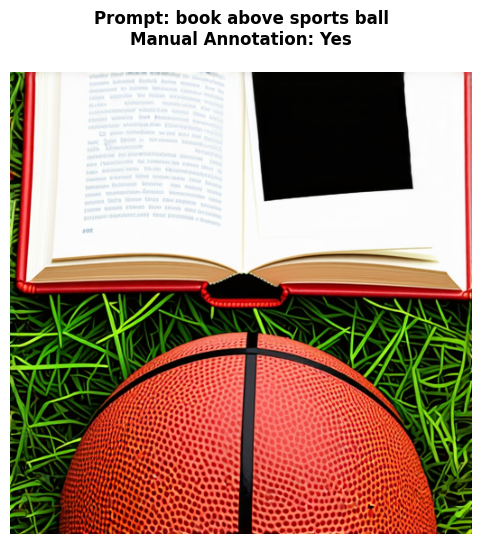

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No,"Result: Yes 1. The book is open and positioned at the top of the image, resting on the green grassy surface. 2. The sports ball is a basketball, located in the lower center of the image, also on the grass. 3. Based on their relative positions, the book is above the sports ball. Conclusion: Yes","Result: Yes Let's analyze the image step by step: 1. **Is the sports ball below the book?** - The book is open and placed on top of the sports ball. - The sports ball is located underneath the book. - Therefore, **yes**, the sports ball is below the book. 2. **If so, then the book is above the sports ball.** - Since the sports ball is below the book, it logically follows that the book is above the sports ball. - This is consistent with the spatial relationship. **Conclusion:** [Yes]"


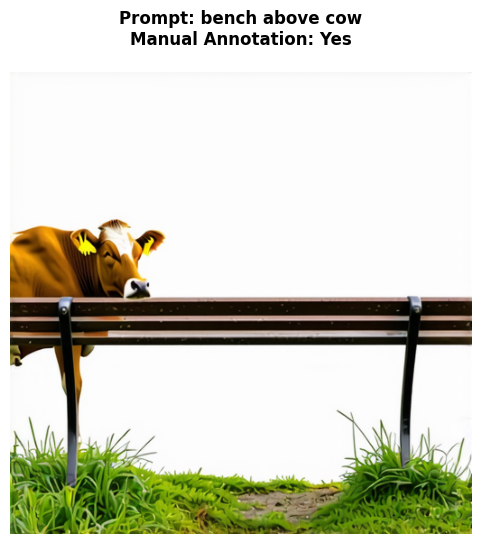

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No,"Result: No 1. The bench is a dark brown wooden bench with metal supports. It is positioned horizontally across the middle of the image, resting on the ground with green grass visible in the foreground. 2. The cow is a brown and white cow with yellow ear tags. It is positioned behind the bench, with its head and upper body visible above the backrest of the bench. 3. Based on their relative positions, the cow's head is above the bench's backrest, while the bench is below the cow's head. However, the main body of the bench is on the ground, and the cow is standing behind it. The bench is not above the cow; rather, the cow is above the bench in terms of vertical placement of its head. Conclusion: No","Result: No Let's analyze the image step by step: 1. **Is the cow below the bench?** - Looking at the image, the cow is positioned behind the bench, with its head and upper body visible above the bench's seat. - The bench is horizontal and appears to be at a higher elevation than the cow's body. - However, the cow's head is clearly above the bench's seat level. - Therefore, the cow is **not entirely below** the bench. In fact, parts of the cow (its head) are above the bench. - So, the cow is **not below the bench**. 2. **If so, then the bench is above the cow.** - This conditional depends on the first statement being true. Since the first statement is false (the cow is not below the bench), this conditional does not apply. **Conclusion:** The cow is not below the bench. The statement ""the cow is below the bench"" is false. Final Answer: **No**."


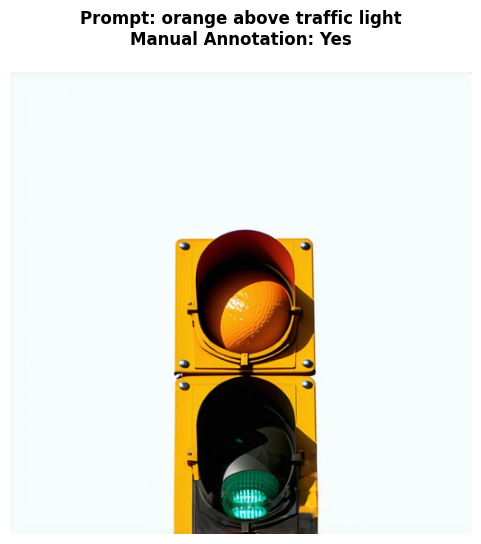

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No,"Result: Yes 1. The orange is a round, textured, orange-colored fruit located inside the top circular housing of the traffic light. 2. The traffic light is a vertical unit with a yellow casing, consisting of two circular lights stacked vertically. The top light is red and contains the orange, while the bottom light is green and illuminated. 3. The orange is inside the top section of the traffic light, which is positioned above the green light. Therefore, the orange is above the traffic light's lower section (the green light). However, since the orange is contained *within* the traffic light structure, its position is technically part of the traffic light. But in terms of relative vertical placement, the orange is above the green light. Conclusion: Yes","Result: Ambiguous Let's analyze the image and the logic step by step. 1. **Is the traffic light below the orange?** - Looking at the image, the orange (a round, textured object) is **inside** the top circular housing of the traffic light. - The traffic light structure surrounds the orange, meaning the orange is **inside** the light fixture, not above or below it in a vertical sense. - However, if we interpret ""below"" as ""positioned lower in space,"" the traffic light is a vertical structure. The orange is in the **top** part of the traffic light. So the **orange is above the lower part** of the traffic light, but the **entire traffic light** is not below the orange — rather, the orange is **part of** the traffic light. - The question is asking: ""Is the traffic light below the orange?"" - The traffic light is a physical object that extends both above and below the orange. But the **main body** of the traffic light (including the green light below) is **below** the orange. - However, the **top of the traffic light** is where the orange is located. So the **traffic light** as"


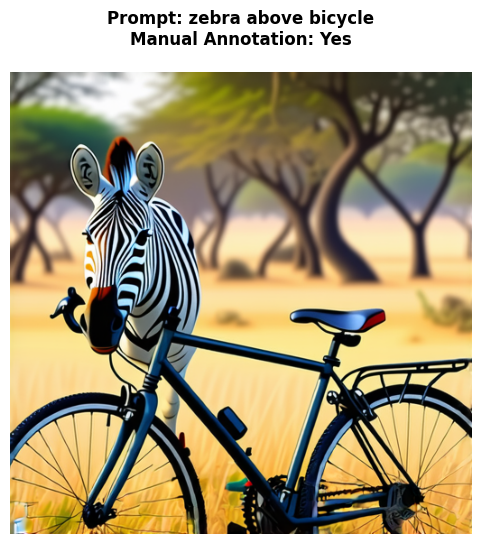

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No,"Result: Yes 1. The zebra is located in the upper-left portion of the image, standing upright and facing forward. Its head and upper body are clearly visible, positioned behind the front wheel and handlebars of the bicycle. 2. The bicycle is in the foreground, positioned in the lower-right portion of the image. It is oriented horizontally, with its frame, wheels, and seat clearly visible. The front wheel and handlebars are on the left, and the rear wheel and seat are on the right. 3. To determine if the zebra is above the bicycle, we compare their vertical positions. The zebra's head is higher than the top of the bicycle's frame and handlebars. The zebra's body extends vertically above the main structure of the bicycle. Therefore, the zebra is positioned above the bicycle. Conclusion: Yes","Result: Yes Let's analyze the image and the spatial relationship between the bicycle and the zebra. 1. **Is the bicycle below the zebra?** - Looking at the image, the zebra is positioned in the background, and the bicycle is in the foreground. - The zebra's head is at a higher vertical level than the bicycle's frame. - The bicycle is clearly in front of and below the zebra in the visual composition. - Therefore, **yes**, the bicycle is below the zebra. 2. **If so, then the zebra is above the bicycle.** - This is a logical consequence of the first statement. If the bicycle is below the zebra, then the zebra is above the bicycle. - This is consistent with the visual evidence. **Conclusion:** [Yes]"


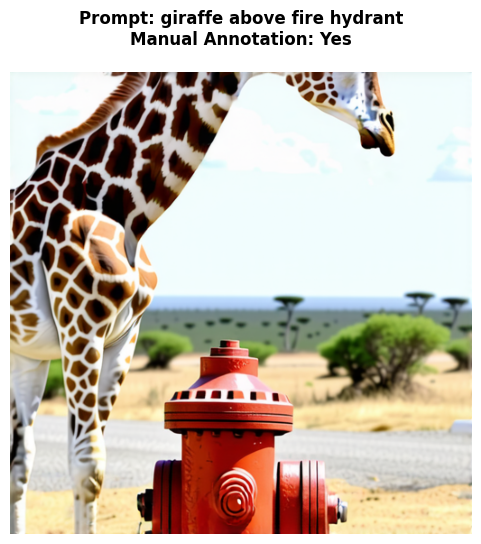

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No,"Result: Ambiguous 1. The giraffe is on the left side of the image, standing with its head and neck extending toward the top right. Its body is positioned vertically, and it occupies the left portion of the frame. 2. The fire hydrant is on the right side of the image, located in the foreground near the bottom center. It is a red fire hydrant positioned on a paved surface. 3. In terms of vertical position (y-coordinate), the giraffe's head is higher in the image than the fire hydrant. However, the giraffe's body extends downward, and its legs are positioned at a lower height than the top of the fire hydrant. The main body of the giraffe (its torso) is roughly at the same vertical level as the fire hydrant. Conclusion: Ambiguous","Result: Yes 1. Is the fire hydrant below the giraffe? Yes — the fire hydrant is positioned lower in the image than the giraffe, which is standing tall. From a visual perspective, the giraffe’s body extends upward from the fire hydrant, placing the fire hydrant below it. 2. If so, then the giraffe is above the fire hydrant. This follows logically from the first statement. Conclusion: **Yes**"


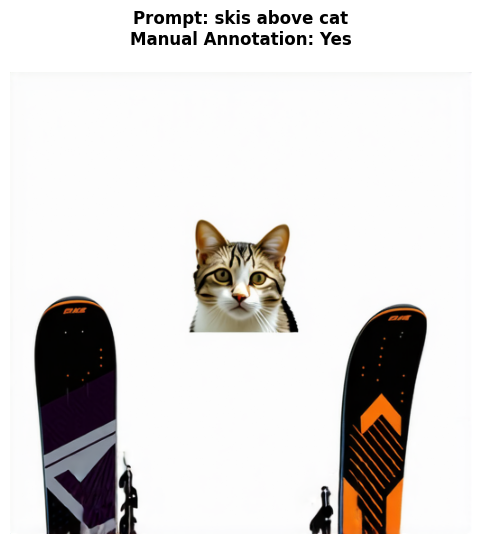

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No.,"Result: No 1. The skis are positioned at the bottom of the image, with one ski on the left and one on the right, forming a V-shape pointing upward. The skis are oriented vertically, with their tips pointing toward the top of the image. 2. The cat is positioned in the center of the image, above the skis and between them. The cat's head is visible, and it is facing forward. 3. Based on their relative coordinates, the skis are below the cat. The skis are at the bottom of the image, while the cat is located in the center, above the skis. Conclusion: No","Result: No Let's analyze the spatial relationship between the cat and the skis. - The image shows a cat's head positioned in the center, between two skis. - The skis are on either side of the cat, extending vertically from the bottom of the image upward. - The cat's head is located **between** the two skis, not directly below or above either one. - However, in terms of vertical alignment, the **cat's head is above the tips of the skis** (which are at the bottom of the image). - Therefore, the cat is **not below** the skis — it is **above** them. Now, addressing the two questions: 1. **Is the cat below the skis?** → No. The cat is above the skis. 2. **If so, then the skis is above the cat.** → The ""if"" condition is false (the cat is not below the skis), so the conditional statement does not apply. Conclusion: **No**."


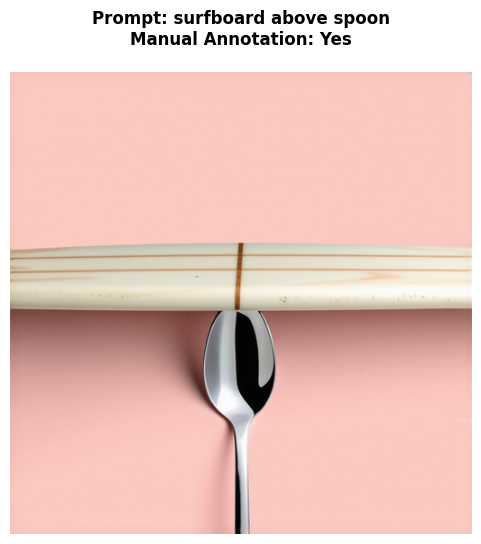

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No.,"Result: Yes 1. The surfboard is a long, light-colored object with a central brown line and two parallel brown stripes. It is positioned horizontally across the upper portion of the image, spanning nearly the full width. 2. The spoon is a metallic object with a reflective bowl and a handle. It is positioned vertically in the lower central part of the image, with its bowl facing upward and its handle extending downward. 3. To determine if the surfboard is above the spoon, we compare their vertical positions. The surfboard is located in the upper half of the image, while the spoon is in the lower half. The surfboard is clearly positioned higher in the frame than the spoon. Conclusion: Yes","Result: Yes Let's analyze the image and the statements step by step. 1. **Is the spoon below the surfboard?** - Looking at the image, the surfboard is positioned horizontally across the top portion of the frame. - The spoon is positioned vertically, with its bowl at the bottom and the handle extending upward. - The spoon's bowl is clearly below the surfboard, and the surfboard is resting on top of the spoon's handle. - Therefore, **yes**, the spoon is below the surfboard. 2. **If so, then the surfboard is above the spoon.** - This is a logical consequence of the first statement. If the spoon is below the surfboard, then the surfboard must be above the spoon. - This is **correct** based on spatial reasoning. Conclusion: **Yes**"


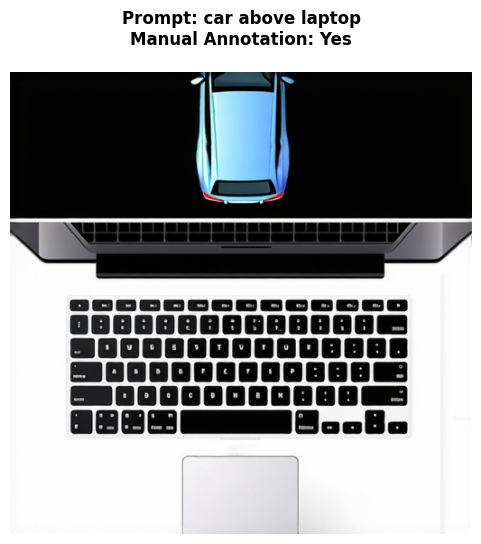

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No,"Result: No 1. The car is a blue vehicle depicted on the laptop's screen, shown from a top-down perspective. It is positioned at the top center of the image, within the display area of the laptop. 2. The laptop is the entire device visible in the image, including the screen, keyboard, and trackpad. It occupies the majority of the frame, with the screen at the top and the keyboard and trackpad below. 3. The car is displayed on the screen, which is above the keyboard and trackpad. Therefore, in terms of the image's vertical layout, the car is above the laptop's physical components (like the keyboard). However, the car is not physically above the laptop; it is a digital image displayed on the screen. Conclusion: No","Result: Ambiguous Let's analyze the image and the spatial relationship between the laptop and the car. 1. **Is the laptop below the car?** - The image shows a laptop with a screen. On the screen, there is an image of a car (top-down view). - The car is displayed *on* the screen, which is part of the laptop. - So, the **car is not physically below** the laptop — it is a digital image *on* the laptop's screen. - Therefore, the **laptop is physically below** the car image, but the car is not a physical object below the laptop. However, the question is: ""Is the laptop below the car?"" - If we interpret ""car"" as the physical object, there is no physical car in the scene — only a picture of one. - If we interpret ""car"" as the image on the screen, then the image is *on* the screen, which is above the keyboard and trackpad (the physical laptop). - So the **laptop (its body) is below the screen**, and the **car image is on the screen**. Therefore, the **laptop is below the car image**. So the"


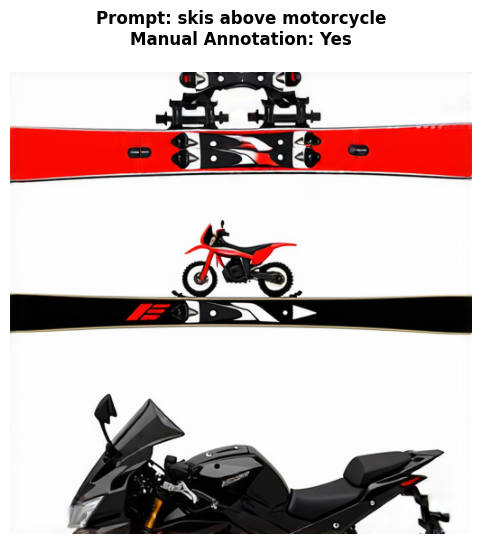

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No,"Result: Yes 1. The skis are the red and black object at the top of the image, positioned horizontally. They are located in the upper portion of the frame. 2. The motorcycle is the black sportbike at the bottom of the image, positioned horizontally. It is located in the lower portion of the frame. 3. Based on their relative coordinates, the skis are above the motorcycle. Conclusion: Yes","Result: Ambiguous Let's analyze the spatial arrangement of the objects in the image: 1. **Identify the objects and their positions:** - At the top: A pair of red skis with bindings. - In the middle: A red dirt bike (motorcycle) positioned on a black ski. - At the bottom: A black sport motorcycle. 2. **Answer the first question: ""Is the motorcycle below the skis?""** - The red skis are at the top of the image. - The red dirt bike (motorcycle) is in the middle, directly below the skis. - The black sport motorcycle is at the bottom, also below the skis. - So, **yes**, there is a motorcycle (the red dirt bike) below the skis. 3. **Second statement: ""If so, then the skis is above the motorcycle.""** - This is logically consistent with the first statement. If the motorcycle is below the skis, then the skis are above the motorcycle. - This holds true for the red dirt bike. 4. **Conclusion:** - The first statement is **true** (a motorcycle is below the skis). - The second statement follows logically and is"


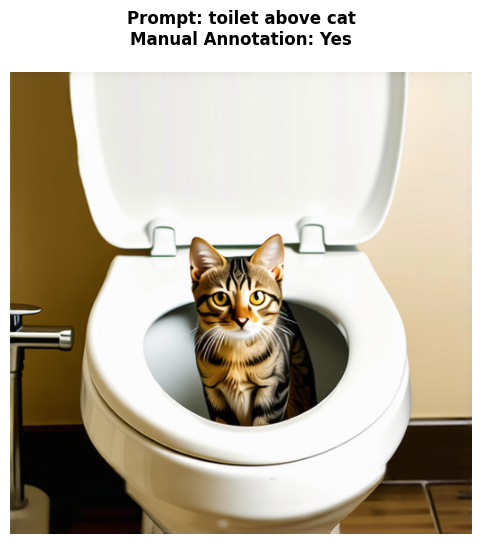

DIRECT STRATEGY,EXPERT STRATEGY,INVERSE STRATEGY
Result: No No,"Result: Yes 1. The toilet is a white ceramic fixture with the lid open, positioned centrally in the image. It occupies the majority of the frame, with its bowl and seat clearly visible. 2. The cat is a tabby cat with distinct stripes and yellow eyes. It is sitting inside the toilet bowl, facing forward, and is positioned in the center of the image, within the opening of the toilet. 3. To determine if the toilet is above the cat, we analyze their relative positions. The cat is inside the toilet bowl, meaning it is physically lower than the top of the toilet structure. The toilet's lid, seat, and upper body extend above the cat's position. Therefore, the toilet as a whole is spatially above the cat. Conclusion: Yes","Result: Yes Let's analyze the image and the questions step by step. 1. **Is the cat below the toilet?** - The cat is sitting inside the toilet bowl, which is the lower part of the toilet structure. - The toilet seat and lid are open and above the cat. - Therefore, the cat is spatially located below the main structure of the toilet (specifically, below the seat and lid). → **Yes**, the cat is below the toilet. 2. **If so, then the toilet is above the cat.** - This is a logical consequence of the first statement. If the cat is below the toilet, then the toilet must be above the cat. → This statement is **correct** based on the spatial relationship. Conclusion: [Yes]"


In [20]:
# ===== EXECUTION =====
MODEL = 'cogvlm'
PHRASE = 'above'
STRATEGIES = ['direct', 'expert', 'inverse']
# STRATEGIES = ['direct', 'expert']
N_IMAGES = 10
START_AT = 0

comp_df = build_comparison_view(MODEL, PHRASE, STRATEGIES, n=N_IMAGES, start=START_AT)
show_comparison_grid(comp_df, STRATEGIES)